# 01 · EDA — pronóstico de ventas (filial México)

Fase 1 de DECISIONES.md (§2, §12). Entrada: tablas de `data/processed/` generadas por `src/preparar.py`.

**Recordatorios de la línea base**
- Target: unidades de `Venta Producto` por `id_articulo` y mes (venta bruta, sell-in). Eje temporal = `fechafactura`.
- Horizonte h = 3 → en el modelado solo lags ≥ 3. Aquí, en el EDA, se mira la historia completa.
- Holdout de prueba: sep-2025 → sep-2026. Las **clasificaciones de SKU (ABC/XYZ/ADI)** de este notebook se calculan
  solo con datos **≤ ago-2025** para que puedan reutilizarse en el modelado sin leakage.
- **Dormidos:** SKUs con ≥ 12 meses sin venta. No son obsoletos: la empresa conserva stock de repuesto para clientes
  con equipos antiguos y se espera que algunos vuelvan a venderse. No se evalúa su pronóstico; se reporta su
  comportamiento (reactivaciones).
- **Proyecto/base:** no hay etiqueta en el catálogo; se usa la clase Syntetos–Boylan como proxy (grumosa/intermitente =
  proyecto: venta intermitente y a veces muy grande; suave/errática = base: venta más constante).
- Marcadores (solo de reporte, sin atribuir causa): `pico_2018_10`, `caida_2019`, `pico_2023_10`, `caida_2024` y los
  meses bajos del total detectados con la regla causal de `features.meses_bajos` (como mínimo `caida_2020_04_05`).
- Sin descripciones de producto ni nombres de cliente: solo claves (`id_articulo`, familia, `CLxxxx`).

In [ ]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from estilo import aplicar, COLORES, AZUL, GRIS, GRIS_CLARO, AZULES, MESES, FMT_MILES
import features as ft
from features import H                       # horizonte del pronóstico (3 meses)

aplicar()
warnings.filterwarnings("ignore", message="Mean of empty slice")   # medianas móviles sobre ventanas vacías al inicio de cada SKU
pd.set_option("display.width", 200, "display.max_columns", 40)
PROC = RAIZ / "data" / "processed"
FIG = RAIZ / "reports" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(FIG / f"{nombre}.png")

ventas = pd.read_parquet(PROC / "ventas.parquet")
dev = pd.read_parquet(PROC / "devoluciones.parquet")
panel = pd.read_parquet(PROC / "panel.parquet")
precio = pd.read_parquet(PROC / "precio_sku_mes.parquet")
resumen = json.loads((PROC / "resumen_preparacion.json").read_text(encoding="utf-8"))

FIN_TRAIN = pd.Timestamp("2025-08-01")      # último mes antes del holdout
INICIO_TEST = pd.Timestamp("2025-09-01")
COVID = (pd.Timestamp("2020-03-01"), pd.Timestamp("2022-12-01"))   # régimen externo: limpiar/interpretar, no predictor (LOG #16)
# Marcadores de reporte (no features, sin atribuir causa): nombre → (inicio, fin)
ts = pd.Timestamp
MARCAS = {"pico_2018_10": (ts("2018-10-01"), ts("2018-10-01")), "caida_2019": (ts("2019-01-01"), ts("2019-12-01")),
          "pico_2023_10": (ts("2023-10-01"), ts("2023-10-01")), "caida_2024": (ts("2024-01-01"), ts("2024-12-01"))}
# meses anormalmente bajos del total: misma regla causal que usa el modelado (features.meses_bajos)
tot_mes = panel.groupby("mes").unidades.sum().reindex(ft.MESES, fill_value=0)
BAJO, FACTOR_BAJO = ft.meses_bajos(tot_mes.to_numpy())
MARCAS.update({n: (ms[0], ms[-1]) for n, ms in ft.nombres_bajos(BAJO).items()})
print("Marcadores:", {n: f"{a:%Y-%m}" + (f"…{b:%Y-%m}" if b != a else "") for n, (a, b) in MARCAS.items()})

def marcar(ax, texto=True):
    for n, (a, b) in MARCAS.items():
        col = COLORES[1] if n.startswith("caida") else COLORES[2]
        ax.axvspan(a - pd.DateOffset(days=12), b + pd.DateOffset(days=12), color=col, alpha=.12, lw=0)
        if texto:
            ax.text(a, ax.get_ylim()[1], n, va="top", fontsize=7, color=GRIS, rotation=90)

Marcadores: {'pico_2018_10': '2018-10', 'caida_2019': '2019-01…2019-12', 'pico_2023_10': '2023-10', 'caida_2024': '2024-01…2024-12', 'caida_2020_04_05': '2020-04…2020-05'}


## 1. Calidad de datos y limpieza

In [ ]:
pasos = pd.Series({k: resumen[k] for k in ["filas_crudas", "tras_dup_completos", "tras_dup_clave", "tras_corte_oct2026"]})
print(pasos.to_frame("filas").assign(quitadas=lambda d: -d.filas.diff()).to_string())
print()
print(f"Líneas Venta Producto: {resumen['venta_lineas']:,}  ·  unidades: {resumen['venta_unidades']:,.0f}")
print(f"Líneas Venta Producto con cantidad ≤ 0 (excluidas): {resumen['venta_lineas_cantidad_no_positiva']}")
print(f"Factura con fecha distinta a la orden: {resumen['pct_factura_distinta_orden']:.2%}  (desfase máx. {resumen['desfase_max_dias']} días)")
print(f"SKUs: {resumen['skus']:,}  ·  familias: {resumen['familias']}  ·  clientes (clave unificada): {resumen['clientes']:,}  ·  id_cliente crudos: {resumen['clientes_id_crudo']:,}")
print("Origen del precio SKU-mes (§9):", resumen["precio_origen"])

                      filas  quitadas
filas_crudas        1399950       NaN
tras_dup_completos  1398797    1153.0
tras_dup_clave      1398741      56.0
tras_corte_oct2026  1395115    3626.0

Líneas Venta Producto: 1,311,647  ·  unidades: 18,184,174
Líneas Venta Producto con cantidad ≤ 0 (excluidas): 36
Factura con fecha distinta a la orden: 0.16%  (desfase máx. 28 días)
SKUs: 2,417  ·  familias: 89  ·  clientes (clave unificada): 3,074  ·  id_cliente crudos: 2,844
Origen del precio SKU-mes (§9): {'mxn': 96879, 'sin_precio': 23, 'sku_6m': 18}


**Lectura:** la fecha de orden y la de factura casi siempre coinciden, así que elegir `fechafactura` como eje (§6)
no mueve unidades entre meses de forma material.

In [ ]:
# Chequeo de la clave de cliente (src/clientes.py) contra id_cliente
m = ventas.groupby("id_cliente").cliente.nunique()
k = ventas.groupby("cliente").id_cliente.nunique()
print(f"id_cliente con >1 clave unificada: {(m > 1).sum()} de {len(m)}  ({ventas[ventas.id_cliente.isin(m[m > 1].index)].cantidad.sum() / ventas.cantidad.sum():.1%} de las unidades)")
print(f"claves unificadas que agrupan >1 id_cliente: {(k > 1).sum()} de {len(k)}")
print("id_cliente partidos en varias claves:", m[m > 1].to_dict())

id_cliente con >1 clave unificada: 3 de 2844  (0.0% de las unidades)
claves unificadas que agrupan >1 id_cliente: 59 de 3074
id_cliente partidos en varias claves: {np.int64(0): 295, np.int64(15305): 2, np.int64(15563): 2}


**Lectura:** la clave unificada junta 59 casos de un mismo cliente con varios `id_cliente`. Solo `id_cliente = 0` se
parte en muchas claves: es un id comodín que aparece en may–sep 2026 (ultimos_meses) con nombres distintos y pocas
unidades. Por eso hay más claves (3,074) que ids (2,844) sin que eso afecte el análisis.

## 2. Serie temporal total

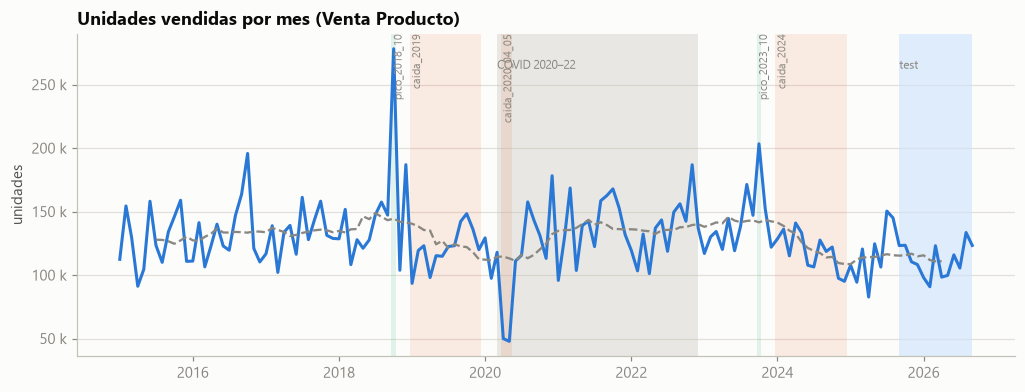

mes                  2015    2016    2017    2018    2019    2020    2021    2022    2023    2024    2025   2026
miles de unidades  1534.0  1602.0  1598.0  1786.0  1456.0  1392.0  1675.0  1627.0  1700.0  1429.0  1397.0  988.0
var_pct               NaN     4.4    -0.2    11.7   -18.5    -4.4    20.3    -2.9     4.5   -15.9    -2.2  -29.3


In [ ]:
mensual = ventas.groupby("mes").cantidad.sum()
anual = ventas.groupby(ventas.mes.dt.year).cantidad.sum()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.axvspan(*COVID, color=GRIS_CLARO, alpha=.35, lw=0)
ax.axvspan(INICIO_TEST, mensual.index.max(), color=AZULES[0], alpha=.6, lw=0)
ax.plot(mensual.index, mensual.values, color=AZUL)
ax.plot(mensual.index, mensual.rolling(12, center=True).mean(), color=GRIS, lw=1.5, ls="--")
ax.yaxis.set_major_formatter(FMT_MILES)
ax.set_title("Unidades vendidas por mes (Venta Producto)")
marcar(ax)
for x, t in [(COVID[0], "COVID 2020–22"), (INICIO_TEST, "test")]:
    ax.text(x, ax.get_ylim()[1] * .93, t, va="top", fontsize=8, color=GRIS)
ax.set_ylabel("unidades")
guardar(fig, "01_serie_total"); plt.show()

print((anual / 1e3).round(0).to_frame("miles de unidades").assign(var_pct=(anual.pct_change() * 100).round(1)).T.to_string())

Línea punteada: media móvil centrada de 12 meses. Marcadores (solo de reporte, sin atribuir causa): COVID 2020–2022
(gris), caídas (naranja: `caida_2019`, `caida_2024` y los meses bajos detectados), picos (`pico_2018_10`,
`pico_2023_10`) y holdout (azul).

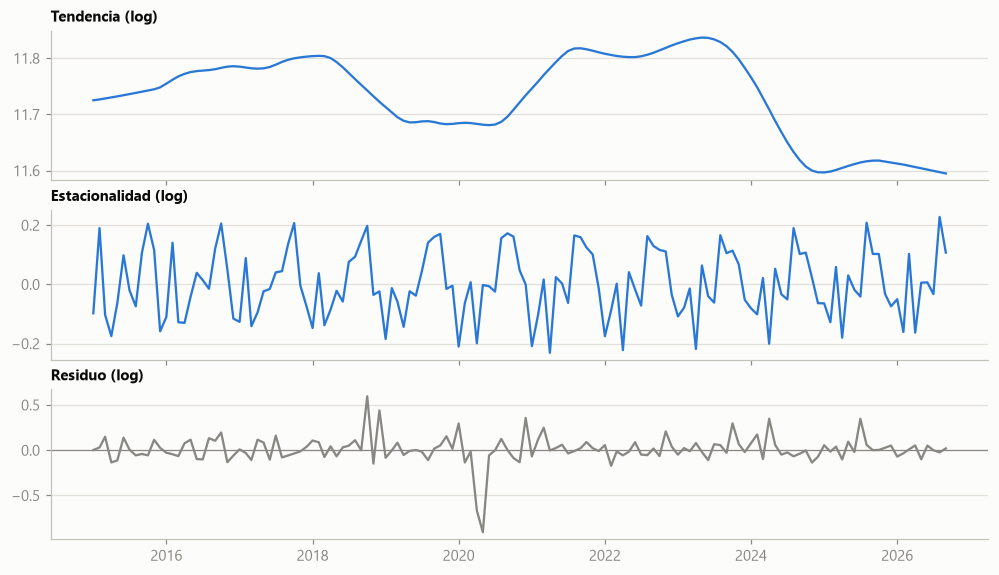

Fuerza de estacionalidad: 0.42  ·  fuerza de tendencia: 0.24  (0 = nada, 1 = domina)


In [ ]:
stl = STL(np.log1p(mensual), period=12, robust=True).fit()
fig, axs = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for ax, serie, t in zip(axs, [stl.trend, stl.seasonal, stl.resid], ["Tendencia (log)", "Estacionalidad (log)", "Residuo (log)"]):
    ax.plot(serie.index, serie.values, color=AZUL if t != "Residuo (log)" else GRIS, lw=1.5)
    ax.set_title(t, fontsize=10)
axs[2].axhline(0, color=GRIS, lw=.8)
guardar(fig, "02_stl"); plt.show()

fuerza_est = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
fuerza_ten = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
print(f"Fuerza de estacionalidad: {fuerza_est:.2f}  ·  fuerza de tendencia: {fuerza_ten:.2f}  (0 = nada, 1 = domina)")

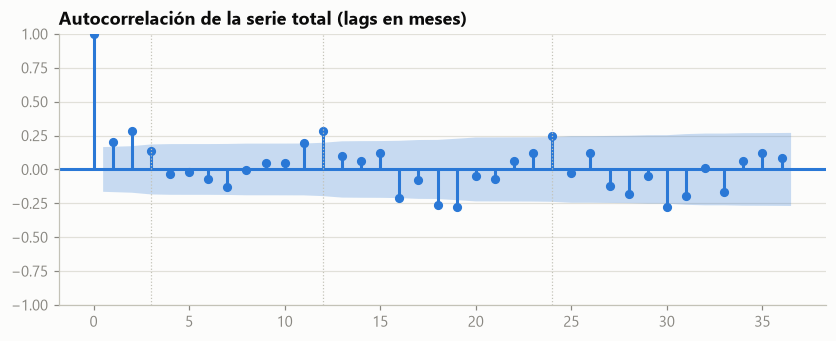

ACF lag 3/12/24: [np.float64(0.14), np.float64(0.3), np.float64(0.28)]


In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.2))
plot_acf(mensual, lags=36, ax=ax, color=AZUL, vlines_kwargs={"colors": AZUL}, alpha=.05)
ax.set_title("Autocorrelación de la serie total (lags en meses)")
for l in (H, 12, 24):
    ax.axvline(l, color=GRIS_CLARO, lw=.8, ls=":")
guardar(fig, "03_acf_total"); plt.show()
print(f"ACF lag {H}/12/24:", [round(mensual.autocorr(l), 2) for l in (H, 12, 24)])

### 2.1 Heatmap estacional (índice mes / media del año)

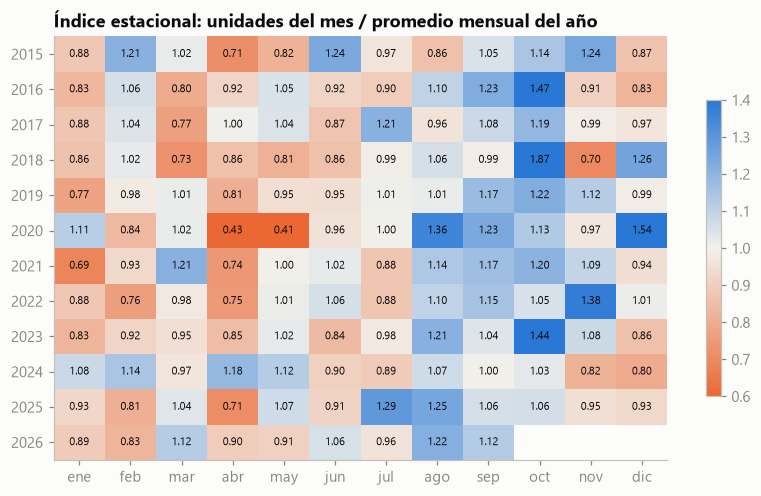

Índice mediano por mes (2015–2025): {'ene': 0.88, 'feb': 0.98, 'mar': 0.98, 'abr': 0.81, 'may': 1.01, 'jun': 0.92, 'jul': 0.98, 'ago': 1.1, 'sep': 1.08, 'oct': 1.19, 'nov': 0.99, 'dic': 0.94}
Participación H2 (jul–dic) por año: mediana 54.4%, rango 46.7%–60.3%
Mes pico por año: {2015: 'nov', 2016: 'oct', 2017: 'jul', 2018: 'oct', 2019: 'oct', 2020: 'dic', 2021: 'mar', 2022: 'nov', 2023: 'oct', 2024: 'abr', 2025: 'jul', 2026: 'ago'}


In [ ]:
tabla = mensual.to_frame("u").assign(a=lambda d: d.index.year, m=lambda d: d.index.month)
idx = tabla.pivot(index="a", columns="m", values="u")
idx = idx.div(idx.mean(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(9, 5))
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("div", [COLORES[1], "#f2f1ec", AZUL])
im = ax.imshow(idx.values, cmap=cmap, norm=TwoSlopeNorm(1, .6, 1.4), aspect="auto")
ax.set_xticks(range(12), MESES); ax.set_yticks(range(len(idx)), idx.index)
for i in range(idx.shape[0]):
    for j in range(idx.shape[1]):
        if not np.isnan(idx.iat[i, j]):
            ax.text(j, i, f"{idx.iat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="#0b0b0b")
ax.grid(False); ax.set_title("Índice estacional: unidades del mes / promedio mensual del año")
fig.colorbar(im, ax=ax, shrink=.7)
guardar(fig, "04_heatmap_estacional"); plt.show()

perfil = idx.loc[:2025].median()      # sin 2026 (año incompleto: termina en sep)
print("Índice mediano por mes (2015–2025):", dict(zip(MESES, perfil.round(2))))
t25 = tabla[tabla.a <= 2025]
h2 = t25[t25.m >= 7].groupby("a").u.sum() / t25.groupby("a").u.sum()
print(f"Participación H2 (jul–dic) por año: mediana {h2.median():.1%}, rango {h2.min():.1%}–{h2.max():.1%}")
print("Mes pico por año:", idx.idxmax(axis=1).map(lambda m: MESES[m - 1]).to_dict())

### 2.2 Por familia

89 familias. Top-7 concentran 69.7%; top-20 93.8% de las unidades.


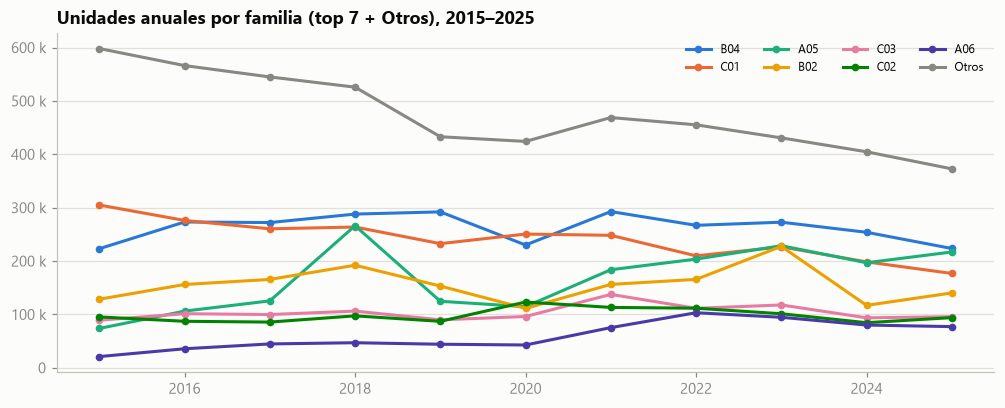

Correlación del perfil estacional de cada familia con el del total:
B04      0.79
C01      0.76
A05      0.89
B02      0.76
C03      0.82
C02      0.62
A06      0.90
Otros    0.90


In [ ]:
fam_tot = ventas.groupby("familia").cantidad.sum().sort_values(ascending=False)
print(f"{len(fam_tot)} familias. Top-7 concentran {fam_tot.head(7).sum() / fam_tot.sum():.1%}; top-20 {fam_tot.head(20).sum() / fam_tot.sum():.1%} de las unidades.")
top = fam_tot.head(7).index
fm = (ventas.assign(f=ventas.familia.where(ventas.familia.isin(top), "Otros"))
      .groupby(["mes", "f"]).cantidad.sum().unstack().fillna(0)[list(top) + ["Otros"]])
anual_f = fm.groupby(fm.index.year).sum().loc[:2025]

fig, ax = plt.subplots(figsize=(11, 4))
for c, col in zip(anual_f.columns, COLORES):
    ax.plot(anual_f.index, anual_f[c], color=col if c != "Otros" else GRIS, marker="o", ms=4, label=c)
ax.yaxis.set_major_formatter(FMT_MILES); ax.legend(ncol=4, fontsize=8)
ax.set_title("Unidades anuales por familia (top 7 + Otros), 2015–2025")
guardar(fig, "05_familias_anual"); plt.show()

# ¿la forma estacional es común entre familias? correlación del perfil mensual de cada familia top con el total
def perfil_fam(s):
    t = s.to_frame("u").assign(a=s.index.year, m=s.index.month)
    t = t[t.a <= 2025].pivot(index="a", columns="m", values="u")
    return t.div(t.mean(axis=1), axis=0).median()
perfiles = pd.DataFrame({c: perfil_fam(fm[c]) for c in fm.columns})
print("Correlación del perfil estacional de cada familia con el del total:")
print(perfiles.corrwith(perfil).round(2).to_string())

## 3. Ciclo de vida e intermitencia por SKU

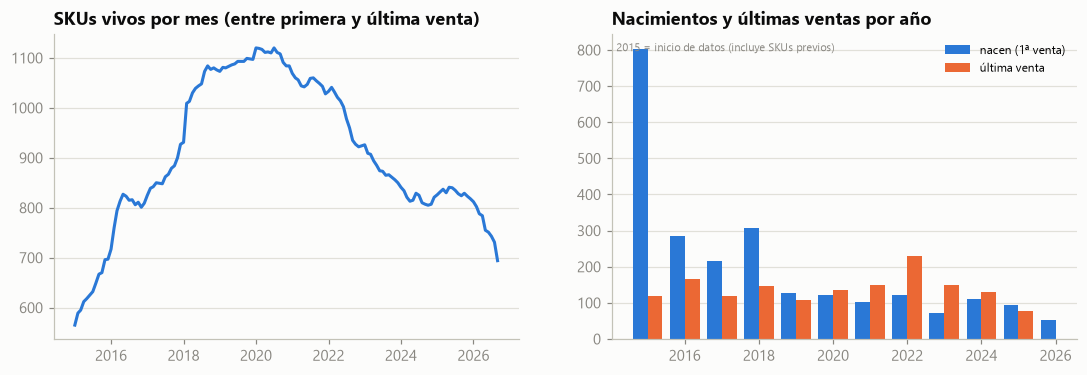

Vida (meses entre 1ª y última venta): mediana 43, p25 14, p75 86
SKUs dormidos al cierre (sin venta en 12 meses a sep-2026): 1,532 de 2,417


In [ ]:
skus = panel.groupby("id_articulo").agg(familia=("familia", "first"), primera=("primera_venta", "first"),
                                         ultima=("ultima_venta", "first"))
nac = skus.primera.dt.year.value_counts().sort_index()
muer = skus[skus.ultima <= pd.Timestamp("2025-09-01")].ultima.dt.year.value_counts().sort_index()
activos = panel[panel.mes <= panel.ultima_venta].groupby("mes").id_articulo.nunique()

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].plot(activos.index, activos.values, color=AZUL)
axs[0].set_title("SKUs vivos por mes (entre primera y última venta)")
w = .4
axs[1].bar(nac.index - w / 2, nac.values, w, color=AZUL, label="nacen (1ª venta)")
axs[1].bar(muer.index + w / 2, muer.values, w, color=COLORES[1], label="última venta")
axs[1].set_title("Nacimientos y últimas ventas por año"); axs[1].legend(fontsize=8)
axs[1].text(.01, .97, "2015 = inicio de datos (incluye SKUs previos)", transform=axs[1].transAxes, fontsize=7, color=GRIS, va="top")
guardar(fig, "06_ciclo_vida"); plt.show()

vida_m = ((skus.ultima.dt.year - skus.primera.dt.year) * 12 + skus.ultima.dt.month - skus.primera.dt.month + 1)
print(f"Vida (meses entre 1ª y última venta): mediana {vida_m.median():.0f}, p25 {vida_m.quantile(.25):.0f}, p75 {vida_m.quantile(.75):.0f}")
print(f"SKUs dormidos al cierre (sin venta en 12 meses a sep-2026): {resumen['skus_dormidos_a_fin']:,} de {resumen['skus']:,}")

### 3.0 SKUs dormidos y reactivaciones

Un SKU está **dormido** tras 12 meses seguidos sin venta. La empresa conserva su stock como repuesto, así que se
espera que algunos vuelvan a venderse. Aquí se mide con toda la historia (solo reporte, no entra al modelado):
cuántos SKUs se durmieron alguna vez, cuántos se reactivaron, cuánto tiempo estuvieron dormidos y cuánto vendieron
al volver. El pronóstico de los dormidos no se evalúa (quedan fuera del set del backtest); su reactivación se reporta
en `cobertura.csv` del backtest.

In [ ]:
vm = ventas.groupby(["id_articulo", "mes"]).cantidad.sum().reset_index().sort_values(["id_articulo", "mes"])
vm["meses_desde_prev"] = vm.groupby("id_articulo").mes.diff().dt.days.div(30.44).round()
react = vm[vm.meses_desde_prev >= 13].copy()             # ≥ 12 meses en cero entre dos ventas → reactivación
react["meses_dormido"] = react.meses_desde_prev - 1
# unidades de los 12 meses desde la reactivación
por_sku = {k: g.set_index("mes").cantidad for k, g in vm[vm.id_articulo.isin(react.id_articulo)].groupby("id_articulo")}
react["u_12m_tras_reactivar"] = [por_sku[r.id_articulo].loc[r.mes:r.mes + pd.DateOffset(months=11)].sum()
                                 for r in react.itertuples()]
durmieron = set(react.id_articulo) | set(skus.index[skus.ultima <= ft.MESES[-1] - pd.DateOffset(months=12)])
print(f"SKUs que se durmieron alguna vez: {len(durmieron):,} de {len(skus):,}")
print(f"Reactivaciones (venta tras ≥ 12 meses sin venta): {len(react):,} eventos en {react.id_articulo.nunique():,} SKUs "
      f"({react.id_articulo.nunique() / len(durmieron):.0%} de los que se durmieron)")
print("Meses dormido antes de reactivar:", react.meses_dormido.describe(percentiles=[.5, .9])[["50%", "90%", "max"]].to_dict())
print(f"Unidades vendidas en los 12 meses tras reactivar: {react.u_12m_tras_reactivar.sum():,.0f} "
      f"({react.u_12m_tras_reactivar.sum() / ventas.cantidad.sum():.2%} del total); mediana por evento "
      f"{react.u_12m_tras_reactivar.median():.0f} u.")
print("Reactivaciones por año:", react.mes.dt.year.value_counts().sort_index().to_dict())

SKUs que se durmieron alguna vez: 1,618 de 2,417
Reactivaciones (venta tras ≥ 12 meses sin venta): 503 eventos en 389 SKUs (24% de los que se durmieron)
Meses dormido antes de reactivar: {'50%': 20.0, '90%': 42.0, 'max': 116.0}
Unidades vendidas en los 12 meses tras reactivar: 12,529 (0.07% del total); mediana por evento 2 u.
Reactivaciones por año: {2016: 10, 2017: 22, 2018: 51, 2019: 49, 2020: 62, 2021: 57, 2022: 64, 2023: 53, 2024: 48, 2025: 64, 2026: 23}


### 3.1 Clases Syntetos–Boylan (datos ≤ ago-2025)

ADI y CV² se calculan **solo con los meses hasta la última venta dentro del entrenamiento**: los ceros posteriores a la
última venta no son intermitencia, son el SKU dormido (o en camino a dormirse). La misma definición, causal, se usa
en el modelado (`features.clase_sb_causal`). Las clases se reportan por separado para **activos** (venta en los
últimos 12 meses de train, sep-2024 → ago-2025) y **dormidos** (sin venta en esos 12 meses).

In [ ]:
tr = panel[panel.mes <= FIN_TRAIN]

def metricas(g):
    g = g.sort_values("mes")
    ult = g.mes[g.unidades > 0].max()
    hasta = g[g.mes <= ult] if pd.notna(ult) else g      # sin los ceros posteriores a la última venta
    y = hasta.unidades.to_numpy()
    nz = y[y > 0]
    n = len(y)
    adi = n / len(nz) if len(nz) else np.inf
    cv2 = (nz.std() / nz.mean()) ** 2 if len(nz) > 1 else np.nan
    cv = y.std() / y.mean() if y.mean() > 0 else np.nan
    yt = g.unidades.to_numpy()                           # vida activa completa (para % de ceros)
    return pd.Series({"meses": n, "meses_con_venta": len(nz), "pct_ceros": 1 - len(nz) / n, "adi": adi,
                      "cv2": cv2, "cv": cv, "unidades": y.sum(), "ultima_venta_train": ult,
                      "ceros_tras_ultima": len(yt) - n})

met = tr.groupby("id_articulo")[["mes", "unidades"]].apply(metricas)
met = met.join(skus)
met["estado"] = np.where(met.ultima_venta_train > FIN_TRAIN - pd.DateOffset(months=12), "activo", "dormido")

def sb(r):
    if r.meses_con_venta < 2: return "insuficiente"
    if r.adi < 1.32: return "suave" if r.cv2 < .49 else "errática"
    return "intermitente" if r.cv2 < .49 else "grumosa"
met["clase_sb"] = met.apply(sb, axis=1)
met["tipo"] = met.clase_sb.map({"grumosa": "proyecto (proxy)", "intermitente": "proyecto (proxy)",
                                "suave": "base", "errática": "base"}).fillna("insuficiente")
print(f"SKUs con historia ≤ ago-2025: {len(met):,} · activos {(met.estado == 'activo').sum():,} · "
      f"dormidos {(met.estado == 'dormido').sum():,}")
for e, d in met.groupby("estado"):
    print(f"\n{e.upper()}: {len(d):,} SKUs")
    print(d.clase_sb.value_counts().to_frame("skus").assign(pct=lambda x: (x.skus / x.skus.sum() * 100).round(1),
          pct_unidades=d.groupby("clase_sb").unidades.sum() / d.unidades.sum() * 100).round(1).to_string())
    print("tipo:", d.tipo.value_counts().to_dict())
print("\nCeros posteriores a la última venta que ya no cuentan en el ADI: "
      f"{met.ceros_tras_ultima.sum():,} SKU-mes (mediana por dormido {met[met.estado == 'dormido'].ceros_tras_ultima.median():.0f})")

SKUs con historia ≤ ago-2025: 2,339 · activos 870 · dormidos 1,469

ACTIVO: 870 SKUs
              skus   pct  pct_unidades
clase_sb                              
errática       500  57.5          32.0
grumosa        159  18.3           0.7
suave          157  18.0          67.2
intermitente    41   4.7           0.0
insuficiente    13   1.5           0.0
tipo: {'base': 657, 'proyecto (proxy)': 200, 'insuficiente': 13}

DORMIDO: 1,469 SKUs
              skus   pct  pct_unidades
clase_sb                              
grumosa        439  29.9          15.7
errática       360  24.5          57.5
intermitente   295  20.1           1.4
insuficiente   267  18.2           0.8
suave          108   7.4          24.6
tipo: {'proyecto (proxy)': 734, 'base': 468, 'insuficiente': 267}

Ceros posteriores a la última venta que ya no cuentan en el ADI: 19,327 SKU-mes (mediana por dormido 12)


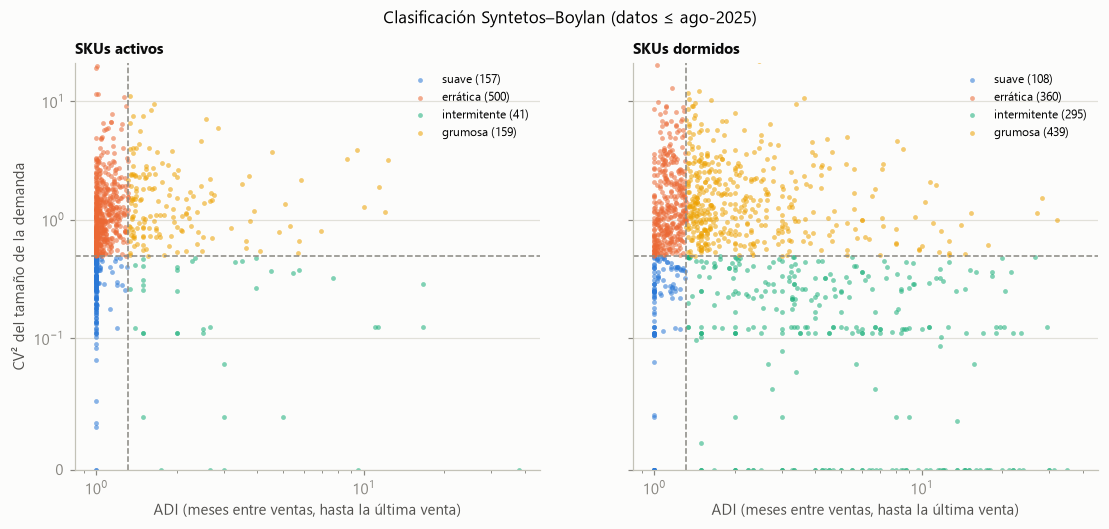

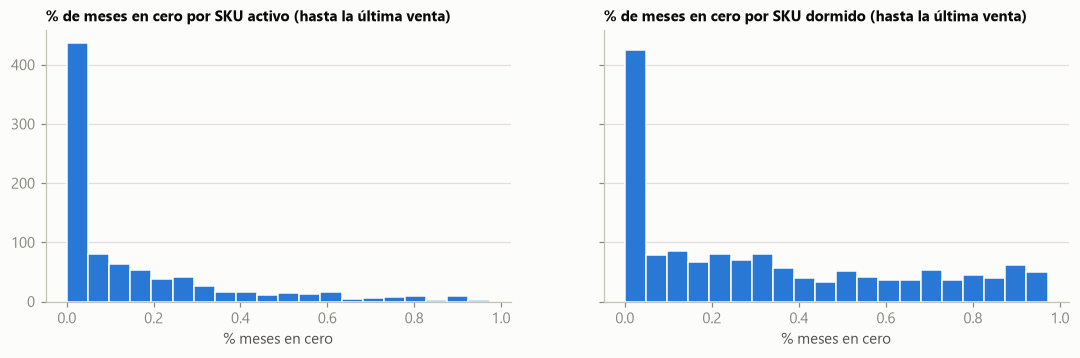

In [ ]:
vis = met[met.clase_sb != "insuficiente"]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
for ax, e in zip(axs, ["activo", "dormido"]):
    for c, col in zip(["suave", "errática", "intermitente", "grumosa"], COLORES):
        d = vis[(vis.clase_sb == c) & (vis.estado == e)]
        ax.scatter(d.adi, d.cv2, s=10, color=col, alpha=.55, label=f"{c} ({len(d)})", lw=0)
    ax.axvline(1.32, color=GRIS, lw=1, ls="--"); ax.axhline(.49, color=GRIS, lw=1, ls="--")
    ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=.1); ax.set_ylim(bottom=0)
    ax.set_xlabel("ADI (meses entre ventas, hasta la última venta)"); ax.set_title(f"SKUs {e}s", fontsize=10)
    ax.legend(fontsize=8)
axs[0].set_ylabel("CV² del tamaño de la demanda")
fig.suptitle("Clasificación Syntetos–Boylan (datos ≤ ago-2025)", fontsize=11)
guardar(fig, "07_adi_cv2"); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, e in zip(axs, ["activo", "dormido"]):
    ax.hist(met[met.estado == e].pct_ceros, bins=20, color=AZUL, edgecolor="#fcfcfb")
    ax.set_title(f"% de meses en cero por SKU {e} (hasta la última venta)", fontsize=10); ax.set_xlabel("% meses en cero")
guardar(fig, "08_pct_ceros"); plt.show()

### 3.2 ABC × XYZ

- **ABC** por valor de consumo (unidades × precio MXN) en los **últimos 12 meses de train** (sep-2024 → ago-2025),
  para SKUs vivos en ese periodo. A = 80 % acumulado del valor, B = siguiente 15 %, C = último 5 %.
- **XYZ** por CV de la demanda mensual en los últimos 24 meses de train: X < 0.5, Y 0.5–1.0, Z > 1.0. Dos versiones:
  - `xyz` (principal): CV de la serie **dividida entre su mediana móvil centrada de 13 meses** (calculada solo con
    datos ≤ ago-2025; si la mediana es 0, la media). Quita el nivel, así que el cambio de nivel de caida_2024 no infla
    la variabilidad.
  - `xyz_crudo`: CV de la serie tal cual (versión anterior).

In [ ]:
ini12, ini24 = FIN_TRAIN - pd.DateOffset(months=11), FIN_TRAIN - pd.DateOffset(months=23)
v12 = ventas[(ventas.mes >= ini12) & (ventas.mes <= FIN_TRAIN)].groupby(["id_articulo", "mes"]).cantidad.sum().reset_index()
v12 = v12.merge(precio, on=["id_articulo", "mes"], how="left")
valor = (v12.cantidad * v12.precio_mxn).groupby(v12.id_articulo).sum().sort_values(ascending=False)
acum = valor.cumsum() / valor.sum()
abc = pd.cut(acum, [0, .8, .95, 1.0001], labels=["A", "B", "C"]).rename("abc")

def cv(s):
    return s.std() / s.mean() if s.mean() > 0 else np.nan

def normalizada(s):
    # serie / mediana móvil centrada de 13 meses, con datos ≤ FIN_TRAIN (tr ya está cortado)
    s = s.set_index("mes").unidades
    med = s.rolling(13, center=True, min_periods=7).median()
    base = med.where(med > 0, s.rolling(13, center=True, min_periods=7).mean())
    return (s / base).replace([np.inf, -np.inf], np.nan)

p_tr = tr[tr.id_articulo.isin(abc.index)]
norm_ = p_tr.groupby("id_articulo")[["mes", "unidades"]].apply(normalizada).rename("r").reset_index()
norm_ = norm_[norm_.mes >= ini24]
cv24_norm = norm_.groupby("id_articulo").r.agg(lambda s: s.std() / s.mean() if s.mean() > 0 else np.nan)
p24 = p_tr[p_tr.mes >= ini24]
cv24 = p24.groupby("id_articulo").unidades.agg(cv)
cortes = [-np.inf, .5, 1.0, np.inf]
xyz = pd.cut(cv24_norm, cortes, labels=["X", "Y", "Z"]).rename("xyz")
xyz_crudo = pd.cut(cv24, cortes, labels=["X", "Y", "Z"]).rename("xyz_crudo")

clas = pd.concat([abc, xyz, xyz_crudo, cv24_norm.rename("cv24_norm"), cv24.rename("cv24"), valor.rename("valor_mxn_12m")],
                 axis=1).join(met[["clase_sb", "tipo", "estado", "adi", "cv2", "pct_ceros", "familia"]])
for col in ["xyz", "xyz_crudo"]:
    n = pd.crosstab(clas.abc, clas[col], margins=True, margins_name="total")
    val = pd.crosstab(clas.abc, clas[col], values=clas.valor_mxn_12m, aggfunc="sum", normalize=True).mul(100).round(1)
    print(f"[{col}] SKUs por celda:"); print(n.to_string()); print()
    print(f"[{col}] % del valor de consumo por celda:"); print(val.to_string()); print()
print("Migración XYZ crudo (filas) → normalizado (columnas):")
print(pd.crosstab(clas.xyz_crudo, clas.xyz, margins=True, margins_name="total").to_string()); print()
print("Clase Syntetos–Boylan dentro de cada ABC (n SKUs):")
print(pd.crosstab(clas.abc, clas.clase_sb).to_string())
clas.reset_index().to_parquet(PROC / "clasificacion_sku.parquet", index=False)

[xyz] SKUs por celda:
xyz      X    Y    Z  total
abc                        
A       77   87   43    207
B       29  105   74    208
C        7   93  310    410
total  113  285  427    825

[xyz] % del valor de consumo por celda:
xyz     X     Y     Z
abc                  
A    41.7  25.9  12.8
B     2.3   7.6   5.1
C     0.2   1.9   2.6

[xyz_crudo] SKUs por celda:
xyz_crudo   X    Y    Z  total
abc                           
A          71   95   42    208
B          18  119   75    212
C           8  108  330    446
total      97  322  447    866

[xyz_crudo] % del valor de consumo por celda:
xyz_crudo     X     Y     Z
abc                        
A          40.6  26.6  12.7
B           1.4   8.7   5.0
C           0.2   2.0   2.8

Migración XYZ crudo (filas) → normalizado (columnas):
xyz          X    Y    Z  total
xyz_crudo                      
X           87    5    0     92
Y           26  255   26    307
Z            0   25  401    426
total      113  285  427    825

Clase Syn

## 4. Anomalías y regímenes

Marcadores genéricos, sin atribuir causa: `pico_2018_10`, `caida_2019`, `pico_2023_10`, `caida_2024` y los meses
bajos detectados en el total (`caida_2020_04_05`). La hipótesis de que las caídas de 2019 y 2024 fueran un ajuste
tras una sobre-compra del año previo **se descartó**, así que aquí solo se describe quién y qué explica cada pico o
caída. COVID 2020–2022 es régimen externo (sirve para limpiar e interpretar, no como predictor). Ninguno de estos
marcadores entra al modelo como feature; los meses bajos del total sí se excluyen como objetivo de entrenamiento y se
suben al piso en la serie limpia (§4.5).

In [ ]:
ym = mensual.to_frame("u").assign(a=mensual.index.year, m=mensual.index.month)
piv = ym.pivot(index="m", columns="a", values="u")
yoy = (piv / piv.shift(axis=1) - 1) * 100
print("Variación % vs mismo mes del año anterior (años de interés):")
print(yoy[[2019, 2020, 2021, 2022, 2024, 2025, 2026]].round(1).set_axis(MESES).T.to_string())

# ¿la contracción viene de menos SKUs vendiendo o de menos unidades por SKU?
por_a = ventas[ventas.mes.dt.year <= 2025].groupby(ventas.mes.dt.year).agg(u=("cantidad", "sum"), skus=("id_articulo", "nunique"),
                                                                          clientes=("cliente", "nunique"), lineas=("cantidad", "size"))
por_a["u_por_sku"] = por_a.u / por_a.skus
por_a["u_por_cliente"] = por_a.u / por_a.clientes
print(); print(por_a.round(0).astype(int).to_string())

Variación % vs mismo mes del año anterior (años de interés):
       ene   feb   mar    abr    may   jun   jul   ago   sep   oct   nov   dic
a                                                                             
2019 -27.3 -21.3  13.8  -23.3   -4.8 -10.1 -16.9 -21.8  -3.4 -46.7  31.2 -35.8
2020  38.4 -18.4  -4.2  -49.1  -58.5  -3.2  -5.6  28.0   0.7 -11.6 -16.9  48.5
2021 -25.9  33.2  42.9  107.5  191.0  28.4   5.9   0.6  13.6  28.0  35.1 -26.0
2022  24.6 -20.4 -21.5   -2.4   -1.5   0.6  -3.0  -5.7  -4.0 -15.2  22.3   4.0
2024   9.8   4.6 -14.3   17.3   -7.8  -9.6 -23.2 -25.6 -19.3 -40.0 -36.0 -22.0
2025 -16.1 -30.7   4.7  -41.4   -6.5  -1.3  41.4  13.7   3.9   1.1  13.3  13.9
2026  -9.1  -3.8   2.1   19.0  -20.0   9.0 -29.9  -7.9   0.1   NaN   NaN   NaN

            u  skus  clientes  lineas  u_por_sku  u_por_cliente
mes                                                            
2015  1533626   804       450  133449       1907           3408
2016  1601669   938       448  1373

### 4.1 Picos: pico_2018_10 y pico_2023_10

Diferencia del mes pico contra la mediana del mismo mes en los años vecinos, desglosada por cliente, familia y SKU.
Solo describe quién explica el pico; **no se infiere que el pico cause la caída siguiente**. No se borra el dato.

pico_2018_10: 278,249 u.  Diferencia vs mismo mes de (2016, 2017, 2019): +120,090 u.
  top-3 cliente: {'CL0001': 48421, 'CL0004': 35654, 'CL0008': 9411}  → 78% de la diferencia; top-10: 98%
  top-3 familia: {'A05': 67725, 'C01': 11204, 'C02': 6618}  → 71% de la diferencia; top-10: 94%
  top-3 id_articulo: {np.int64(1597): 63773, np.int64(3866): 6545, np.int64(1981): 5766}  → 63% de la diferencia; top-10: 78%
pico_2023_10: 203,362 u.  Diferencia vs mismo mes de (2021, 2022): +48,235 u.
  top-3 cliente: {'CL0003': 18039, 'CL0005': 16380, 'CL0002': 7553}  → 87% de la diferencia; top-10: 112%
  top-3 familia: {'C01': 10109, 'A05': 10104, 'A06': 9236}  → 61% de la diferencia; top-10: 105%
  top-3 id_articulo: {np.int64(245): 9374, np.int64(1981): 3530, np.int64(1500): 3042}  → 33% de la diferencia; top-10: 62%


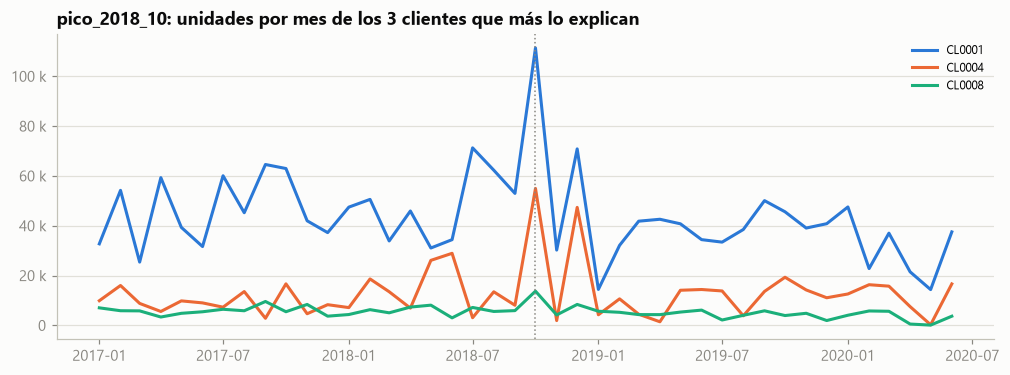

In [ ]:
def sobre_vecinos(mes, refs, por):
    """Unidades del mes − mediana del mismo mes en los años de referencia, por la dimensión `por`."""
    t = ventas.groupby([por, "mes"]).cantidad.sum().unstack(fill_value=0)
    meses_ref = [pd.Timestamp(f"{a}-{mes.month:02d}-01") for a in refs]
    return (t[mes] - t[meses_ref].median(axis=1)).sort_values(ascending=False)

for nombre, refs in [("pico_2018_10", (2016, 2017, 2019)), ("pico_2023_10", (2021, 2022))]:
    M = MARCAS[nombre][0]
    dif = mensual[M] - np.median([mensual[pd.Timestamp(f"{a}-{M.month:02d}-01")] for a in refs])
    print(f"{nombre}: {mensual[M]:,.0f} u.  Diferencia vs mismo mes de {refs}: {dif:+,.0f} u.")
    for por in ["cliente", "familia", "id_articulo"]:
        e = sobre_vecinos(M, refs, por)
        print(f"  top-3 {por}: {e.head(3).round(0).astype(int).to_dict()}  → {e.head(3).sum() / dif:.0%} de la diferencia; "
              f"top-10: {e.head(10).sum() / dif:.0%}")

M18 = MARCAS["pico_2018_10"][0]
top_cli = sobre_vecinos(M18, (2016, 2017, 2019), "cliente").head(3).index
mc = ventas[ventas.cliente.isin(top_cli)].groupby(["mes", "cliente"]).cantidad.sum().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3.6))
z = mc.loc["2017-01-01":"2020-06-01"]
for c, col in zip(top_cli, COLORES):
    ax.plot(z.index, z[c], color=col, label=c)
ax.axvline(M18, color=GRIS, lw=1, ls=":"); ax.yaxis.set_major_formatter(FMT_MILES); ax.legend(fontsize=8)
ax.set_title("pico_2018_10: unidades por mes de los 3 clientes que más lo explican")
guardar(fig, "12_oct2018_clientes"); plt.show()

### 4.2 Caídas: caida_2019 y caida_2024

In [ ]:
nivel = mensual.groupby(mensual.index.year).mean()
print("Promedio mensual 2017–2018: {:,.0f}  ·  2019: {:,.0f}  ({:+.1%})".format(
    nivel.loc[2017:2018].mean(), nivel.loc[2019], nivel.loc[2019] / nivel.loc[2017:2018].mean() - 1))
print("Promedio mensual 2021–2023: {:,.0f}  ·  2024–2025: {:,.0f}  ({:+.1%})".format(
    nivel.loc[2021:2023].mean(), nivel.loc[2024:2025].mean(), nivel.loc[2024:2025].mean() / nivel.loc[2021:2023].mean() - 1))
pf = ventas.groupby([ventas.mes.dt.year.rename("a"), "familia"]).cantidad.sum().unstack(0).fillna(0)
for a in (2019, 2024):
    d = (pf[a] - pf[a - 1]).sort_values()
    print(f"\n{a}: familias que más caen vs {a - 1} (unidades):", d.head(5).round(0).astype(int).to_dict(),
          f"→ {d.head(5).sum() / d[d < 0].sum():.0%} de la caída bruta")
print("(El detalle por cliente está en §5.)")

Promedio mensual 2017–2018: 141,010  ·  2019: 121,351  (-13.9%)
Promedio mensual 2021–2023: 138,953  ·  2024–2025: 117,738  (-15.3%)

2019: familias que más caen vs 2018 (unidades): {'A05': -141543, 'B02': -38953, 'C99': -37414, 'C01': -31100, 'C03': -16379} → 76% de la caída bruta

2024: familias que más caen vs 2023 (unidades): {'B02': -110513, 'A05': -31921, 'C01': -28157, 'C03': -24122, 'B04': -18901} → 73% de la caída bruta
(El detalle por cliente está en §5.)


### 4.3 COVID 2020–2022 por familia

Demanda anual por familia, indexada a 2019 = 100. Se muestran las familias con ≥ 0.5 % de las unidades de 2019–2023.
El efecto no es uniforme: hay familias que suben (home-office) y otras que bajan (enterprise).

23 familias = 96% de las unidades 2019–2023
a         2019   2020   2021   2022   2023  covid_vs_2019_%  share_19_23_%
familia                                                                   
A08      100.0  141.0  254.0  448.0  464.0            181.0            1.0
A06      100.0   97.0  171.0  234.0  215.0             67.0            5.0
E01      100.0  126.0  177.0  133.0   88.0             45.0            1.0
C12      100.0  162.0  164.0  105.0   83.0             43.0            1.0
A05      100.0   92.0  147.0  163.0  184.0             34.0           11.0
C02      100.0  142.0  130.0  128.0  116.0             33.0            7.0
C03      100.0  107.0  153.0  124.0  131.0             28.0            7.0
A01      100.0   87.0  131.0  133.0  170.0             17.0            1.0
C11      100.0  126.0  128.0   95.0  165.0             16.0            1.0
C06      100.0  101.0  113.0  121.0  117.0             11.0            3.0
B05      100.0  101.0  114.0  107.0  106.0              

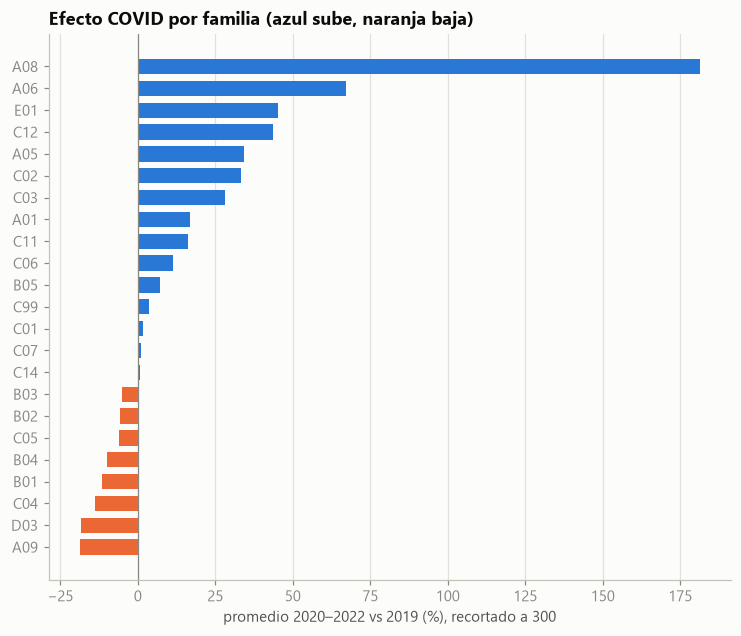

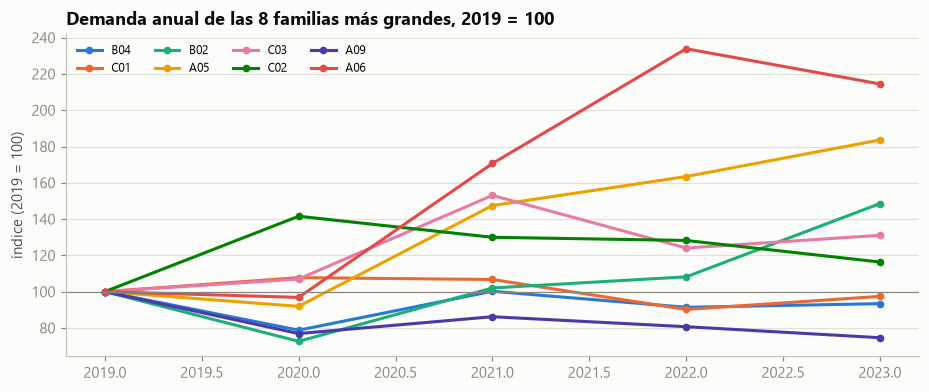

In [ ]:
fa = ventas[ventas.mes.dt.year.between(2019, 2023)].groupby([ventas.mes.dt.year.rename("a"), "familia"]).cantidad.sum().unstack(0).fillna(0)
rel = fa[fa.sum(axis=1) / fa.values.sum() >= .005]
ind = rel.div(rel[2019], axis=0).mul(100).replace(np.inf, np.nan)
ind["covid_vs_2019_%"] = (rel[[2020, 2021, 2022]].mean(axis=1) / rel[2019] - 1) * 100
ind["share_19_23_%"] = rel.sum(axis=1) / fa.values.sum() * 100
ind = ind.sort_values("covid_vs_2019_%", ascending=False)
print(f"{len(rel)} familias = {rel.values.sum() / fa.values.sum():.0%} de las unidades 2019–2023")
print(ind.round(0).to_string())

orden = ind["covid_vs_2019_%"].dropna().clip(-100, 300)
fig, ax = plt.subplots(figsize=(8, max(3, .28 * len(orden))))
ax.barh(orden.index[::-1], orden.values[::-1], color=[AZUL if v >= 0 else COLORES[1] for v in orden.values[::-1]], height=.7)
ax.axvline(0, color=GRIS, lw=.8); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("promedio 2020–2022 vs 2019 (%), recortado a 300")
ax.set_title("Efecto COVID por familia (azul sube, naranja baja)")
guardar(fig, "13_covid_familias"); plt.show()

top8 = rel[2019].sort_values(ascending=False).head(8).index
fig, ax = plt.subplots(figsize=(10, 3.8))
for f, col in zip(top8, COLORES):
    ax.plot(ind.columns[:5], ind.loc[f, ind.columns[:5]], color=col, marker="o", ms=4, label=f)
ax.axhline(100, color=GRIS, lw=.8); ax.set_ylabel("índice (2019 = 100)"); ax.legend(ncol=4, fontsize=8)
ax.set_title("Demanda anual de las 8 familias más grandes, 2019 = 100")
guardar(fig, "14_covid_top8"); plt.show()

**Perfil de familia** (`data/perfil_familia.csv`, curado a mano a partir de `descripcion1` del catálogo; aquí solo
se usan las claves). Perfiles: *enterprise* (cableado estructurado, racks, switches, PoE, KVM, tarjetas
seriales, candados, video corporativo); *home_office* (cables y adaptadores de video, soportes de TV/monitor,
audífonos, cámaras, teclado/mouse, hubs, docks, adaptadores de red USB); *mixto* (PC/consumo general).
La familia se conserva: el perfil es una agrupación adicional para interpretar COVID, no un feature.

Participación de unidades 2019: {'enterprise': 46.1, 'home_office': 24.9, 'mixto': 29.0}
Índice anual por perfil (2019 = 100):
a            2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025
perfil                                                                       
enterprise     88   101   104   111   100    80    98    96   104    83    79
home_office    85    96   103   145   100   104   151   155   163   146   147
mixto         149   137   125   122   100   114   111    99    98    82    79


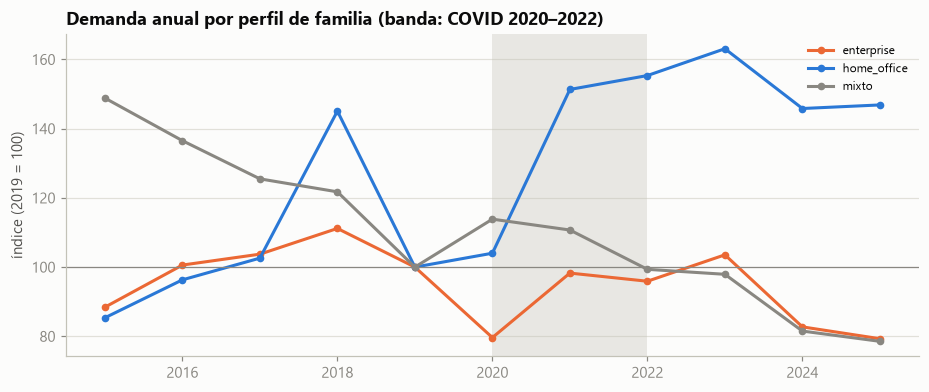


Familias relevantes por perfil y dirección del efecto COVID (n):
col_0        baja  sube
perfil                 
enterprise      8     1
home_office     0     9
mixto           0     5


In [ ]:
perfil = pd.read_csv(RAIZ / "data" / "perfil_familia.csv", dtype=str).set_index("familia")
ventas["perfil"] = ventas.familia.map(perfil.perfil).fillna("mixto")
pa = ventas[ventas.mes.dt.year <= 2025].groupby([ventas.mes.dt.year.rename("a"), "perfil"]).cantidad.sum().unstack().drop(columns="no_producto", errors="ignore")
ip = pa.div(pa.loc[2019]).mul(100)
print("Participación de unidades 2019:", (pa.loc[2019] / pa.loc[2019].sum() * 100).round(1).to_dict())
print("Índice anual por perfil (2019 = 100):"); print(ip.round(0).astype(int).T.to_string())

fig, ax = plt.subplots(figsize=(10, 3.8))
for p_, col in zip(["enterprise", "home_office", "mixto"], [COLORES[1], AZUL, GRIS]):
    ax.plot(ip.index, ip[p_], color=col, marker="o", ms=4, label=p_)
ax.axvspan(2020, 2022, color=GRIS_CLARO, alpha=.35, lw=0); ax.axhline(100, color=GRIS, lw=.8)
ax.set_ylabel("índice (2019 = 100)"); ax.legend(fontsize=8)
ax.set_title("Demanda anual por perfil de familia (banda: COVID 2020–2022)")
guardar(fig, "14b_covid_perfil"); plt.show()

ind["perfil"] = ind.index.map(perfil.perfil)
print("\nFamilias relevantes por perfil y dirección del efecto COVID (n):")
print(pd.crosstab(ind.perfil, np.where(ind["covid_vs_2019_%"] >= 0, "sube", "baja")).to_string())

### 4.4 Estacionalidad robusta

Índice = unidades del mes / mediana móvil centrada de 13 meses (quita nivel y tendencia), resumido por mes del año
con la **mediana** entre años (robusta a oct-2018 o abr-2020) frente a la **media** (clásica). Se excluyen
COVID (2020–2022) y el holdout, y se calcula solo con train (≤ ago-2025). Los índices por familia se guardan
para usarlos en el feature engineering.

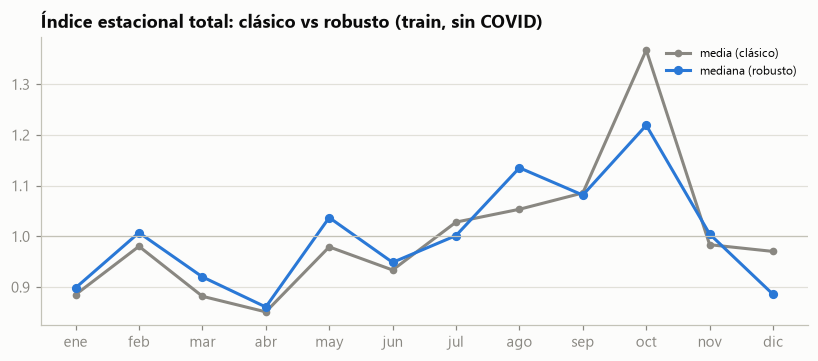

          ene   feb   mar   abr   may   jun   jul   ago   sep   oct   nov   dic
robusto  0.90  1.01  0.92  0.86  1.04  0.95  1.00  1.14  1.08  1.22  1.00  0.89
clasico  0.89  0.98  0.88  0.85  0.98  0.93  1.03  1.05  1.09  1.37  0.98  0.97
dif      0.01  0.03  0.04  0.01  0.06  0.01 -0.03  0.08 -0.00 -0.15  0.02 -0.08
Índice robusto guardado para 44 familias (≥ 36 meses con venta en train).


In [ ]:
def indice_robusto(s, excluir=COVID):
    s = s[s.index <= FIN_TRAIN]
    r = (s / s.rolling(13, center=True, min_periods=7).median()).replace([np.inf, -np.inf], np.nan)
    r = r[(r.index < excluir[0]) | (r.index > excluir[1])].dropna()
    med = r.groupby(r.index.month).median()
    mea = r.groupby(r.index.month).mean()
    return med / med.mean(), mea / mea.mean(), r.groupby(r.index.month).size()

med, mea, n_anos = indice_robusto(mensual)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(range(12), mea.values, color=GRIS, marker="o", ms=4, label="media (clásico)")
ax.plot(range(12), med.values, color=AZUL, marker="o", ms=5, label="mediana (robusto)")
ax.axhline(1, color=GRIS_CLARO, lw=.8); ax.set_xticks(range(12), MESES); ax.legend(fontsize=8)
ax.set_title("Índice estacional total: clásico vs robusto (train, sin COVID)")
guardar(fig, "15_estacional_robusto"); plt.show()
print(pd.DataFrame({"robusto": med, "clasico": mea, "dif": med - mea}).set_axis(MESES).round(2).T.to_string())

fam_m = ventas.groupby(["familia", "mes"]).cantidad.sum().unstack(0).reindex(mensual.index, fill_value=0).fillna(0)
filas = []
for f in fam_m.columns:
    s = fam_m[f]
    if (s[s.index <= FIN_TRAIN] > 0).sum() < 36:        # mínimo 3 años con venta para un índice confiable
        continue
    i, _, n = indice_robusto(s)
    if len(i) == 12:
        filas.append(pd.DataFrame({"familia": f, "mes_del_ano": i.index, "indice": i.values, "n_obs": n.values}))
ie = pd.concat(filas, ignore_index=True)
ie.to_parquet(PROC / "indice_estacional_familia.parquet", index=False)
print(f"Índice robusto guardado para {ie.familia.nunique()} familias (≥ 36 meses con venta en train).")

### 4.5 Outliers por SKU y meses bajos del total

**Picos por SKU.** En log(1 + unidades): residuo frente a la mediana móvil centrada de 13 meses, escalado por la MAD
del SKU (piso 0.25). Outlier = z > 3.5 con venta > 0. **Se marca, no se borra.** La ventana centrada sirve para
interpretar la historia; el modelado usa la versión causal (`features.limpiar_outliers`, solo meses previos).

**Regla nueva:** la limpieza solo se aplica a los SKUs **suaves y erráticos** (clase al origen). En grumosos e
intermitentes (proxy de proyecto) los picos *son* la demanda: la regla marcaba casi toda venta grande. Abajo se
compara la regla anterior (todos los SKUs) con la nueva.

**Meses bajos del total** (la regla de picos solo marca altos): log1p(total) < mediana de los 12 meses previos −
3.5 · IQR/1.349 de los 24 previos (piso de escala 0.1), causal. En esos meses la serie limpia de los SKUs
suaves/erráticos se sube al piso del total y el mes no se usa como objetivo de entrenamiento.

Regla anterior (todos los SKUs), SKU-mes marcados por clase SB:
              sku_mes  mediana_u  unidades   pct
clase_sb                                        
errática         1468       62.0  666815.0  25.0
grumosa          3339       10.0  138716.0  56.9
insuficiente      122        4.0   10104.0   2.1
intermitente      675        3.0   11054.0  11.5
sin_train           9        3.0      84.0   0.2
suave             253       35.0  207520.0   4.3

Regla nueva (suaves y erráticos): 1,721 SKU-mes de 76,090 con venta (2.3%); 4.8% de las unidades; 641 SKUs (antes 5,866 SKU-mes, 5.7% de las unidades)
Meses con más unidades en outliers (% del mes): {Timestamp('2018-10-01 00:00:00'): 32.8, Timestamp('2022-11-01 00:00:00'): 32.4, Timestamp('2023-08-01 00:00:00'): 28.8, Timestamp('2018-12-01 00:00:00'): 28.4, Timestamp('2023-11-01 00:00:00'): 26.3, Timestamp('2018-07-01 00:00:00'): 16.2}


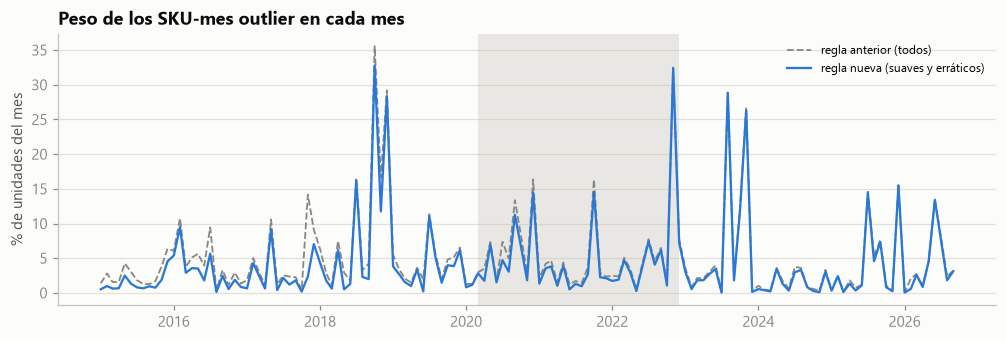


Meses bajos del total detectados (regla causal):
            total  bajo  factor_al_piso
2020-04-01  49930  True            1.44
2020-05-01  47784  True            1.43
Nombres: ['caida_2020_04_05']


In [ ]:
p = panel[["id_articulo", "familia", "mes", "unidades"]].copy()
p["l"] = np.log1p(p.unidades)
p["base"] = p.groupby("id_articulo").l.transform(lambda s: s.rolling(13, center=True, min_periods=7).median())
p["res"] = p.l - p.base
esc = p.groupby("id_articulo").res.transform(lambda r: max(1.4826 * (r - r.median()).abs().median(), .25))
p["z"] = p.res / esc
p["clase_sb"] = p.id_articulo.map(met.clase_sb).fillna("sin_train")
p["marcado_todos"] = (p.z > 3.5) & (p.unidades > 0)                    # regla anterior (v1)
p["outlier"] = p.marcado_todos & p.clase_sb.isin(ft.CLASES_LIMPIAS)     # regla nueva: solo suaves y erráticos
p[["id_articulo", "mes", "unidades", "z", "clase_sb", "marcado_todos", "outlier"]].to_parquet(PROC / "outliers_sku.parquet", index=False)

v1 = p[p.marcado_todos]
print("Regla anterior (todos los SKUs), SKU-mes marcados por clase SB:")
print(v1.groupby("clase_sb").agg(sku_mes=("unidades", "size"), mediana_u=("unidades", "median"),
                                 unidades=("unidades", "sum")).assign(pct=lambda d: (d.sku_mes / d.sku_mes.sum() * 100).round(1)).to_string())
o = p[p.outlier]
con_venta = (p.unidades > 0) & p.clase_sb.isin(ft.CLASES_LIMPIAS)
print(f"\nRegla nueva (suaves y erráticos): {len(o):,} SKU-mes de {con_venta.sum():,} con venta ({len(o) / con_venta.sum():.1%}); "
      f"{o.unidades.sum() / p.unidades.sum():.1%} de las unidades; {o.id_articulo.nunique():,} SKUs "
      f"(antes {len(v1):,} SKU-mes, {v1.unidades.sum() / p.unidades.sum():.1%} de las unidades)")
um = o.groupby("mes").unidades.sum().reindex(mensual.index, fill_value=0) / mensual
um1 = v1.groupby("mes").unidades.sum().reindex(mensual.index, fill_value=0) / mensual
print("Meses con más unidades en outliers (% del mes):", (um.sort_values(ascending=False).head(6) * 100).round(1).to_dict())

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(um1.index, um1.values * 100, color=GRIS, lw=1.2, ls="--", label="regla anterior (todos)")
ax.plot(um.index, um.values * 100, color=AZUL, lw=1.5, label="regla nueva (suaves y erráticos)")
ax.axvspan(*COVID, color=GRIS_CLARO, alpha=.35, lw=0); ax.legend(fontsize=8)
ax.set_ylabel("% de unidades del mes"); ax.set_title("Peso de los SKU-mes outlier en cada mes")
guardar(fig, "16_outliers_mes"); plt.show()

bajos = pd.DataFrame({"total": tot_mes, "bajo": BAJO, "factor_al_piso": FACTOR_BAJO}, index=ft.MESES)
print("\nMeses bajos del total detectados (regla causal):")
print(bajos[bajos.bajo].assign(total=lambda d: d.total.round(0).astype(int), factor_al_piso=lambda d: d.factor_al_piso.round(2)).to_string())
print("Nombres:", list(ft.nombres_bajos(BAJO)))

## 5. Puente de unidades por cliente (año contra año)

      año_previo  nuevos  expansión  contracción  perdidos   año
2016        1534      11        174          -92       -26  1602
2017        1602      26        125         -141       -14  1598
2018        1598      17        298          -73       -55  1786
2019        1786      14         44         -362       -26  1456
2020        1456      43        125         -206       -26  1392
2021        1392      45        305          -59        -8  1675
2022        1675      12         79         -133        -6  1627
2023        1627      15        160          -96        -6  1700
2024        1700       3         39         -253       -61  1429
2025        1429      15         98         -132       -13  1397
            2016  2017  2018  2019  2020  2021  2022  2023  2024  2025
n_nuevos     195   170   261   182   234   169   481   365   271   176
n_perdidos   197   224   179   293   201   242   168   486   378   310


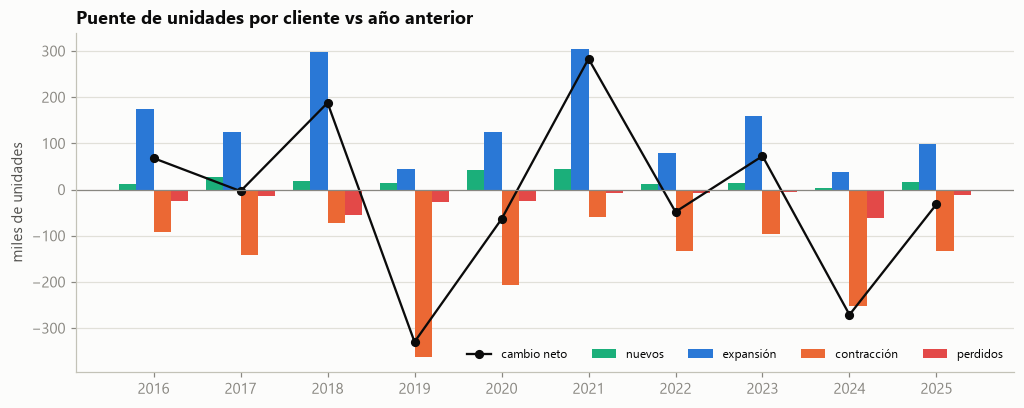

In [ ]:
cy = ventas[ventas.mes.dt.year <= 2025].groupby([ventas.mes.dt.year.rename("a"), "cliente"]).cantidad.sum().unstack(0).fillna(0)

def puente(a):
    prev, cur = cy[a - 1], cy[a]
    d = cur - prev
    return pd.Series({"año_previo": prev.sum(),
                      "nuevos": cur[(prev == 0) & (cur > 0)].sum(),
                      "expansión": d[(prev > 0) & (cur > 0) & (d > 0)].sum(),
                      "contracción": d[(prev > 0) & (cur > 0) & (d < 0)].sum(),
                      "perdidos": -prev[(prev > 0) & (cur == 0)].sum(),
                      "año": cur.sum(),
                      "n_nuevos": int(((prev == 0) & (cur > 0)).sum()), "n_perdidos": int(((prev > 0) & (cur == 0)).sum())})

pt = pd.DataFrame({a: puente(a) for a in range(2016, 2026)}).T
print((pt[["año_previo", "nuevos", "expansión", "contracción", "perdidos", "año"]] / 1e3).round(0).astype(int).to_string())
print(pt[["n_nuevos", "n_perdidos"]].astype(int).T.to_string())

comp = ["nuevos", "expansión", "contracción", "perdidos"]
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(pt)); w = .2
for i, (c, col) in enumerate(zip(comp, [COLORES[2], AZUL, COLORES[1], COLORES[7]])):
    ax.bar(x + (i - 1.5) * w, pt[c] / 1e3, w, color=col, label=c)
ax.plot(x, (pt.año - pt.año_previo) / 1e3, color="#0b0b0b", marker="o", ms=5, lw=1.5, label="cambio neto")
ax.axhline(0, color=GRIS, lw=.8); ax.set_xticks(x, pt.index); ax.set_ylabel("miles de unidades")
ax.set_title("Puente de unidades por cliente vs año anterior"); ax.legend(ncol=5, fontsize=8)
guardar(fig, "09_puente_clientes"); plt.show()

In [ ]:
# caida_2019, caida_2024 y 2025: ¿qué clientes explican cada caída? (descriptivo, sin atribuir causa)
for a in (2019, 2024, 2025):
    d = (cy[a] - cy[a - 1]).sort_values()
    caida = d[d < 0]
    print(f"\n{a}: cambio neto {d.sum() / 1e3:,.0f} k unidades. Top-5 clientes que más caen ({caida.head(5).sum() / caida.sum():.0%} de la caída bruta):")
    print(pd.DataFrame({"prev": cy[a - 1], "año": cy[a], "delta": d}).loc[caida.head(5).index].round(0).astype(int).to_string())

conc = cy.loc[:, 2025].sort_values(ascending=False)
print(f"\nConcentración 2025: top-5 clientes {conc.head(5).sum() / conc.sum():.1%}, top-20 {conc.head(20).sum() / conc.sum():.1%}")
hhi = (cy / cy.sum()).pow(2).sum() * 1e4
print("HHI por año (10,000 = un solo cliente):", hhi.round(0).astype(int).to_dict())


2019: cambio neto -330 k unidades. Top-5 clientes que más caen (87% de la caída bruta):
           prev     año   delta
cliente                        
CL0001   642331  453646 -188685
CL0004   230123  125241 -104882
CL0008    79228   53815  -25413
CL0022    12189       0  -12189
CL0006    72092   63851   -8241

2024: cambio neto -271 k unidades. Top-5 clientes que más caen (84% de la caída bruta):
           prev     año   delta
cliente                        
CL0003   294201  182437 -111764
CL0004   103731   41228  -62503
CL0017    49334       0  -49334
CL0005   162245  136620  -25625
CL0014    24596   10543  -14053

2025: cambio neto -32 k unidades. Top-5 clientes que más caen (79% de la caída bruta):
           prev     año  delta
cliente                       
CL0004    41228    5862 -35366
CL0001   500067  464712 -35355
CL0005   136620  110843 -25777
CL0002   233061  223725  -9336
CL0014    10543    1578  -8965

Concentración 2025: top-5 clientes 76.3%, top-20 97.7%
HHI por año (

## 6. Devoluciones (sub-análisis, §10)

Unidades devueltas por año y concepto:
concepto  Cargos por devolucion (vtas)  Devolución de producto  Garantía de Producto  Rotación de Inventarios  total
a                                                                                                                   
2015                                 0                   26457                  1666                    23711  51834
2016                                 0                   27013                  1699                    24690  53402
2017                                 0                   14645                  2095                    46391  63131
2018                                 0                   44190                  1320                    21205  66715
2019                                 0                   26575                   979                    22570  50124
2020                                 0                   13616                   633                    13908  28157
2021                     

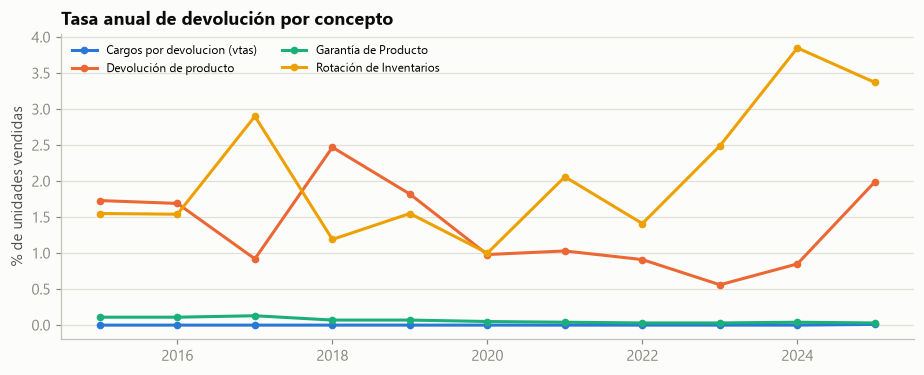

In [ ]:
dev["a"] = dev.mes.dt.year
da = dev[dev.a <= 2025].pivot_table(index="a", columns="concepto", values="unidades_dev", aggfunc="sum").fillna(0)
da["total"] = da.sum(axis=1)
tasa = (da.div(anual.loc[:2025], axis=0) * 100).round(2)
print("Unidades devueltas por año y concepto:"); print(da.round(0).astype(int).to_string())
print("\nTasa = unidades devueltas / unidades vendidas del mismo año (%), neteo anual:"); print(tasa.to_string())

fig, ax = plt.subplots(figsize=(10, 3.6))
cols = [c for c in da.columns if c != "total"]
for c, col in zip(cols, COLORES):
    ax.plot(tasa.index, tasa[c], color=col, marker="o", ms=4, label=c)
ax.set_ylabel("% de unidades vendidas"); ax.legend(fontsize=8, ncol=2)
ax.set_title("Tasa anual de devolución por concepto")
guardar(fig, "10_tasa_devolucion"); plt.show()

Índice estacional mediano de devoluciones (sin rotación): {'ene': 1.2, 'feb': 0.66, 'mar': 1.07, 'abr': 0.59, 'may': 0.77, 'jun': 0.88, 'jul': 0.67, 'ago': 0.91, 'sep': 0.99, 'oct': 0.86, 'nov': 0.72, 'dic': 0.66}
Top-5 clientes concentran 70.3% de las devoluciones (sin rotación); top-20 89.5%
Tasa de devolución de los 5 clientes que más devuelven: {'CL0002': 2.6, 'CL0001': 0.7, 'CL0003': 0.8, 'CL0022': 92.0, 'CL0007': 2.9}
Devoluciones con venta previa del mismo SKU-cliente: 99.1%
Desfase (meses) venta→devolución: {'25%': 0.0, '50%': 0.1, '75%': 0.5, '90%': 2.4}


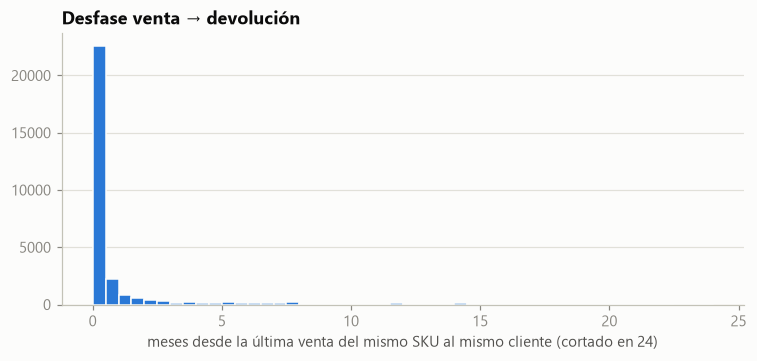

In [ ]:
real = dev[dev.concepto.isin(["Devolución de producto", "Garantía de Producto", "Cargos por devolucion (vtas)"])]
# estacionalidad de devoluciones: índice mensual
dm = real.groupby("mes").unidades_dev.sum().reindex(mensual.index, fill_value=0)
t = dm.to_frame("u").assign(a=dm.index.year, m=dm.index.month)
t = t[t.a <= 2025].pivot(index="a", columns="m", values="u")
print("Índice estacional mediano de devoluciones (sin rotación):", dict(zip(MESES, t.div(t.mean(axis=1), axis=0).median().round(2))))

# concentración por cliente
c = real.groupby("cliente").unidades_dev.sum().sort_values(ascending=False)
print(f"Top-5 clientes concentran {c.head(5).sum() / c.sum():.1%} de las devoluciones (sin rotación); top-20 {c.head(20).sum() / c.sum():.1%}")
tc = (c / ventas.groupby("cliente").cantidad.sum()).dropna()
print("Tasa de devolución de los 5 clientes que más devuelven:", (tc.loc[c.head(5).index] * 100).round(1).to_dict())

# desfase venta → devolución: última venta del mismo SKU al mismo cliente antes de la devolución
s = ventas[["fechafactura", "cliente", "id_articulo"]].sort_values("fechafactura")
r = real[["fechafactura", "cliente", "id_articulo"]].sort_values("fechafactura")
emp = pd.merge_asof(r, s.rename(columns={"fechafactura": "fecha_venta"}), left_on="fechafactura", right_on="fecha_venta",
                    by=["cliente", "id_articulo"], direction="backward")
lag = (emp.fechafactura - emp.fecha_venta).dt.days / 30.44
print(f"Devoluciones con venta previa del mismo SKU-cliente: {lag.notna().mean():.1%}")
print("Desfase (meses) venta→devolución:", lag.describe(percentiles=[.25, .5, .75, .9]).round(1)[["25%", "50%", "75%", "90%"]].to_dict())

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(lag.dropna().clip(upper=24), bins=48, color=AZUL, edgecolor="#fcfcfb")
ax.set_xlabel("meses desde la última venta del mismo SKU al mismo cliente (cortado en 24)")
ax.set_title("Desfase venta → devolución")
guardar(fig, "11_desfase_devolucion"); plt.show()

## 7. Hallazgos

**Datos y limpieza**
- 1.40 M filas → 1.31 M líneas de Venta Producto (18.2 M unidades, ene-2015 → sep-2026). Se quitaron 1,209 duplicados
  y oct-2026 (parcial). Orden y factura difieren solo en 0.16 % de las líneas → el eje `fechafactura` es seguro.
- Precio MXN disponible en > 99.9 % de los SKU-mes; la cascada de §9 casi no se usa.

**Nivel y tendencia**
- Sin crecimiento estructural: 1.4–1.8 M unidades/año. Marcadores de reporte, sin atribuir causa: **caida_2019**
  (−18.5 %) y **caida_2024** (−15.9 %; el promedio mensual pasa de 139 k en 2021–23 a 118 k en 2024–25).
  2025 (−2.2 %) es el mismo nivel bajo, no una contracción aparte. La hipótesis de que estas caídas se deban a una
  sobre-compra del año previo **se descartó**.
- COVID 2020–2022 (régimen externo): abr–may 2020 caen −49 % / −58 % y 2021 rebota (+20 %). La regla causal de meses
  bajos del total marca exactamente **caida_2020_04_05** (z = 3.5): en la serie limpia esos meses se suben al piso
  (× 1.44 / × 1.43) y no se usan como objetivo de entrenamiento.

**Anomalías (§4.1–4.5)**
- **pico_2018_10 (278 k u.):** +120 k u. frente a los octubres vecinos. CL0001 + CL0004 + CL0008 explican el 78 %, la
  familia A05 el 56 % y un solo SKU (1597) el 53 %. Se conserva el dato (no se borra).
- **pico_2023_10 (203 k u.):** +48 k frente a oct-2021/22, con CL0003, CL0005 y CL0002 al frente (87 %).
- **caida_2019 y caida_2024:** en 2019 caen sobre todo A05, B02 y C99 (y los clientes CL0001 −189 k y CL0004 −105 k);
  en 2024, B02, A05 y C01 (CL0003 −112 k, CL0004 −63 k, CL0017 se pierde, −49 k). Es concentración en pocos
  mayoristas, no un patrón que se pueda anticipar con la historia.
- **Estacionalidad robusta:** con medianas y sin COVID, el índice de octubre baja de 1.37 (clásico) a **1.22** y el de
  diciembre de 0.97 a 0.89. El índice clásico está inflado por pico_2018_10. Se guardan índices robustos para 44
  familias (`indice_estacional_familia.parquet`).
- **Outliers por SKU:** con la regla anterior (todos los SKUs) se marcaban 5,866 SKU-mes y el **68 % eran de SKUs
  grumosos o intermitentes**, con tamaños medianos de 10 y 3 unidades: la regla marcaba casi toda venta de proyecto.
  Con la regla nueva (solo suaves y erráticos) quedan **1,721 SKU-mes** (2.3 % de sus meses con venta, 4.8 % de las
  unidades totales). Los meses donde más pesan siguen siendo pico_2018_10 (33 % del mes), nov-2022, ago-2023,
  dic-2018 y nov-2023. Se guardan en `outliers_sku.parquet` (marcados, no borrados, con la marca de ambas reglas).

**COVID por familia (§4.3), 2020–2022 vs 2019**
- Suben: A08 (+181 %), A06 (+67 %), E01, C12, A05, C02, C03 (+28–45 %). E01, C12 y C02 regresan a su nivel o quedan
  por debajo en 2023 (joroba temporal). A06, A05 y A08 siguen arriba (cambio estructural).
- Bajan: A09, D03, C04, B01, B04 (−10 a −19 %). B04 es la familia más grande (17 %). B02 cae en 2020 y se
  recupera después.
- **Por perfil** (`data/perfil_familia.csv`): de las 23 familias relevantes, las 9 *home_office* suben y 8 de 9
  *enterprise* bajan (la excepción es B05, +7 %). Índice 2019 = 100:
  - *enterprise* (46 % de las unidades de 2019): 80 en 2020, se recupera a 96–104 en 2021–23 y cae a 79–83 en
    2024–25. caida_2024 es sobre todo enterprise.
  - *home_office* (25 %): 104 → 151 → 155 → 163, y sigue en ~146 en 2024–25. **El salto de COVID no se revirtió**,
    es un cambio de nivel estructural. (Su 145 de 2018 es el pico de oct-2018, SKU 1597.)
  - *mixto* (29 %): tendencia descendente de largo plazo (149 en 2015 → 79 en 2025), sin efecto COVID claro.
  → Para limpiar 2020–2022 no basta un ajuste uniforme: la dirección depende del perfil.

**Estacionalidad**
- Moderada (fuerza STL 0.42). Patrón mediano: ago–oct fuerte (pico en **oct, índice 1.19**), abril y enero bajos
  (0.81 / 0.88). H2 = 54 % del año (rango 47–60 %). El mes pico cambia de un año a otro.
- Los perfiles de las familias top se parecen al del total (correlación 0.62–0.90). Eso respalda usar un índice
  estacional de familia/total para SKUs con poca historia.
- ACF del total: lag 3 ≈ 0.14 y lag 12 ≈ 0.30. Con h = 3 el lag-3 aporta poco por sí solo; pesan más el nivel
  (ventanas desfasadas) y el lag-12.

**Intermitencia y segmentación (datos ≤ ago-2025; ADI y CV² hasta la última venta)**
- 2,339 SKUs con historia: **870 activos** (venta en sep-2024 → ago-2025) y **1,469 dormidos**. Quitar los ceros
  posteriores a la última venta saca 19,327 SKU-mes del ADI (mediana de 12 por dormido).
- **Activos:** suaves 18 % de los SKUs y **67 % de las unidades**; erráticos 57 % / 32 %. Grumosos e intermitentes
  (proxy de proyecto) son el 23 % de los SKUs y < 1 % de las unidades.
  → El volumen se gana con ETS/SARIMA/modelo global sobre suaves y erráticos. Croston/SBA/TSB aplica a la cola larga.
- **Dormidos:** la mitad son grumosos o intermitentes (proxy de proyecto, 50 %) y 18 % tienen historia insuficiente.
  No se evalúa su pronóstico.
- ABC×XYZ: 207 SKUs A = 80 % del valor. Con el **XYZ normalizado** (serie / mediana móvil de 13 meses) **AX = 77
  SKUs, 42 % del valor** (crudo: 71 SKUs, 41 %); CZ = 310 SKUs (crudo: 330). De 825 SKUs con ambas versiones, 82 %
  queda igual; 51 bajan de clase (26 Y → X y 25 Z → Y, el CV inflado por el cambio de nivel) y 31 suben (26 Y → Z,
  5 X → Y).
- Vida mediana de un SKU: 43 meses. 1,532 de 2,417 SKUs están **dormidos** a sep-2026. No son obsoletos: se
  conserva stock de repuesto. **389 SKUs (24 % de los que se durmieron) se reactivaron** al menos una vez (503
  eventos), tras una mediana de 20 meses dormidos (p90 42), pero con muy poco volumen: mediana de 2 u. por evento y
  12.5 k u. en los 12 meses siguientes (0.07 % del total). Hay unos 880–1,150 SKUs vendiendo cada año.

**Clientes (diagnóstico)**
- Muy concentrado: en 2025 el top-5 = 76 % y el top-20 = 98 % de las unidades.
- 2019: CL0001 (−189 k) y CL0004 (−105 k) explican la mayor parte de la caída. 2024: contracción de clientes existentes
  (−253 k) y clientes perdidos (−61 k). 2025: CL0004 casi desaparece (41 k → 6 k) y quedan 276 clientes activos
  (el mínimo de la serie).
  → Un cambio en 2–3 mayoristas mueve el total. Esto respalda la regla de **ajuste manual** de §8.

**Devoluciones (§10)**
- Tasa anual total (neteo anual) de 2.0–5.4 %, **creciente desde 2022** (2.35 % → 5.40 % en 2025). Suben tanto
  Devolución de producto (0.56 % → 1.99 %) como Rotación de inventarios (≈ 3.4–3.9 % en 2024–25).
- Concentradas: el top-5 de clientes = 70 % de las devoluciones (sin rotación). CL0022 devolvió el 92 % de lo que compró.
- Desfase: en 99 % de los casos hay una venta previa del mismo SKU al mismo cliente. La mediana es de ~0.1 meses
  desde la venta más reciente y el p90 de 2.4 meses (medido contra la venta *más reciente*, así que es un límite
  inferior). Las devoluciones caen cerca de la venta: una **tasa rezagada ≥ 3** como feature es viable para el
  experimento de baseline.
- Estacionalidad de devoluciones: pico en enero (1.20), más bajas en abr / jul / dic.

**Salida para la fase 2:** `data/processed/clasificacion_sku.parquet` (ABC, XYZ normalizado y crudo, clase
Syntetos–Boylan, tipo proyecto/base, estado activo/dormido, ADI, CV² por SKU, calculados solo con train).